# Diabetic Retinopathy using Inception

## 1. Import Library

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
# 1. IMPORT KIẾN TRÚC VÀ HÀM TIỀN XỬ LÝ CỦA INCEPTION
from tensorflow.keras.applications import InceptionV3, InceptionResNetV2, Xception
# Nếu muốn dùng bản lai tạo mạnh mẽ hơn, bạn có thể import InceptionResNetV2
# from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inceptionv3
from tensorflow.keras.applications.inception_resnet_v2 import preprocess_input as preprocess_inc_res
from tensorflow.keras.applications.xception import preprocess_input as preprocess_xcep

I0000 00:00:1785059442.512714   59368 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785059444.204576   59368 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1785059478.917293   59368 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [3]:
BATCH_SIZE=4

In [4]:
with open("../../../data/processed/aptos/sample_50/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [5]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [6]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def create_pipeline(x_data, y_data, preprocess_func):
    def preprocess_wrapper(image, label):
        image = tf.cast(image, tf.float32)
        # Sử dụng hàm tiền xử lý tương ứng được truyền vào
        image = preprocess_func(image)
        return image, label

    with tf.device('/CPU:0'):
        dataset = tf.data.Dataset.from_tensor_slices((x_data, y_data))
        dataset = dataset.map(preprocess_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

In [10]:
# Data cho InceptionV3
train_dataset_inceptionv3 = create_pipeline(x_train, y_train, preprocess_inceptionv3)
val_dataset_inceptionv3 = create_pipeline(x_val, y_val, preprocess_inceptionv3)
test_dataset_inceptionv3 = create_pipeline(x_test, y_test, preprocess_inceptionv3)
# Data cho InceptionResNetV2
train_dataset_inception_resnet_v2 = create_pipeline(x_train, y_train, preprocess_inc_res)
val_dataset_inception_resnet_v2 = create_pipeline(x_val, y_val, preprocess_inc_res)
test_dataset_inception_resnet_v2 = create_pipeline(x_test, y_test, preprocess_inc_res)
# Data cho Xception
train_dataset_xception = create_pipeline(x_train, y_train, preprocess_xcep)
val_dataset_xception = create_pipeline(x_val, y_val, preprocess_xcep)
test_dataset_xception = create_pipeline(x_test, y_test, preprocess_xcep)

I0000 00:00:1785059512.752745   59368 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train

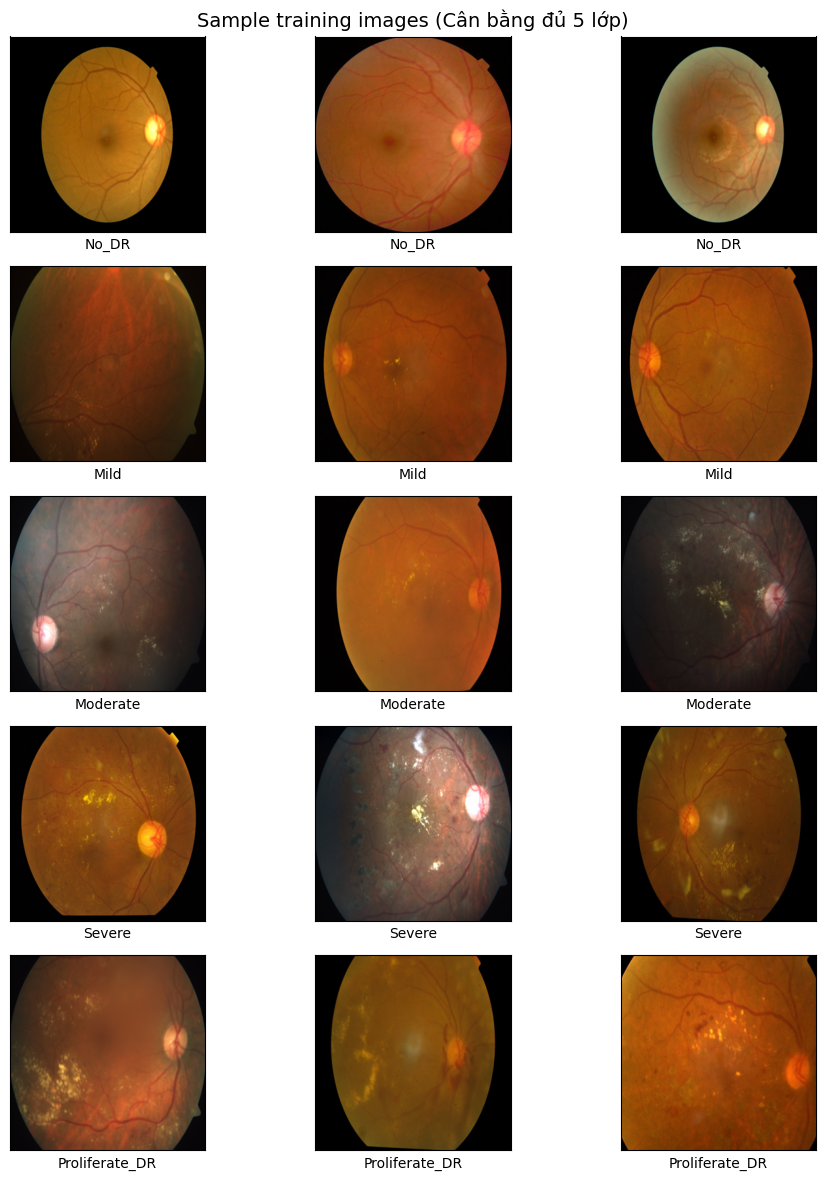

In [11]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

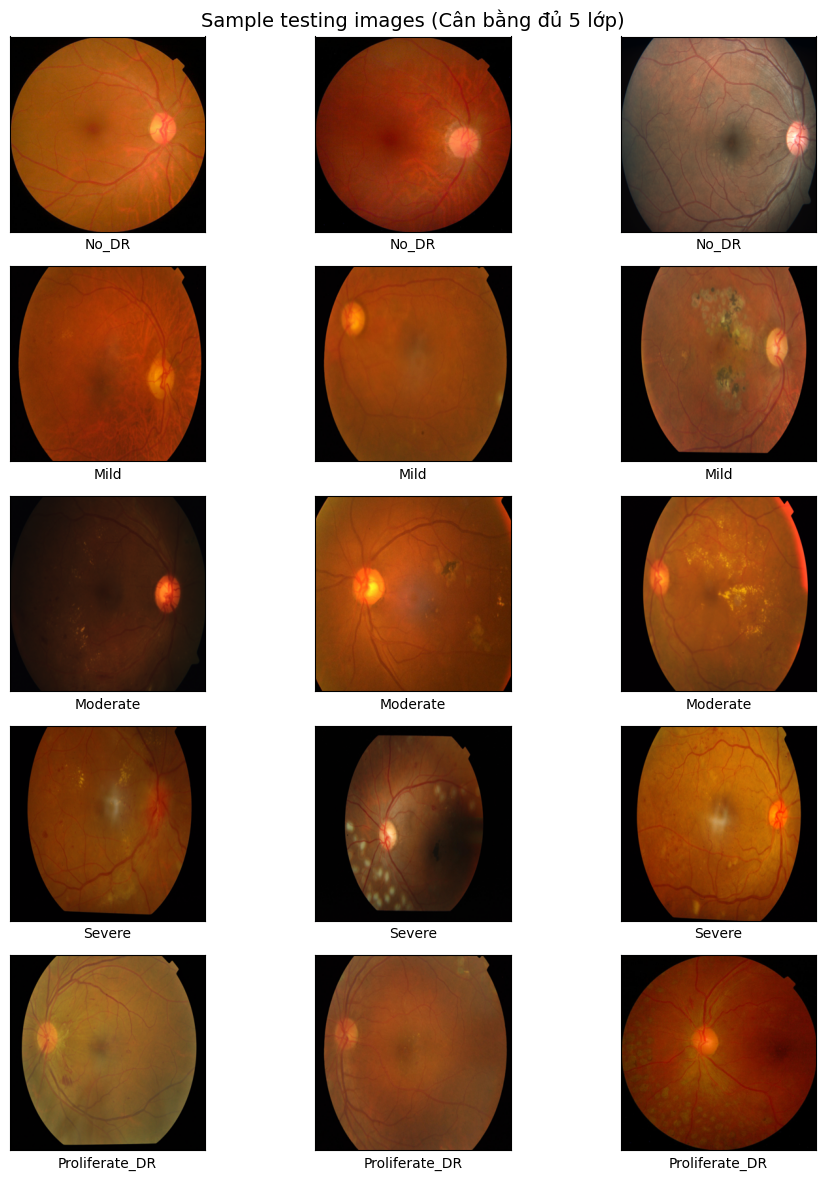

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng các model Inception

In [13]:
def build_model(base_model_class, input_shape, num_classes, model_name):
    # Khởi tạo Base Model 
    base_model = base_model_class(weights='imagenet', 
                                  include_top=False, 
                                  input_shape=input_shape)
    
    # Đóng băng (Freeze) phần thân 
    base_model.trainable = False
    
    # Xây dựng Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x) 
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=model_name)
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 4.1 Xây dựng model InceptionV3

In [14]:
model_inceptionv3 = build_model(InceptionV3, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, "InceptionV3_APTOS_50")
model_inceptionv3.summary()

Model: "InceptionV3_APTOS_50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 149, 149,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 149, 149,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 147, 147,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 147, 147,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 73, 73,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 73, 73,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 71, 71,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 22,994,725 (87.72 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 21,807,904 (83.19 MB)

### 4.2 Xây dựng model InceptionResNetV2

In [15]:
model_inception_resnetv2 = build_model(InceptionResNetV2, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, "InceptionResNetV2_APTOS_50")
model_inception_resnetv2.summary()

Model: "InceptionResNetV2_APTOS_50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_94 (Conv2D)  │ (None, 149, 149,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 149, 149,  │         96 │ conv2d_94[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_94       │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 147, 147,  │      9,216 │ activation_94[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_95[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_95       │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 147, 147,  │     18,432 │ activation_95[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_96[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_96       │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 73, 73,    │          0 │ activation_96[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 73, 73,    │      5,120 │ max_pooling2d_4[… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_97[0][0]   │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_97       │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_98 (Conv2D)  │ (None, 71, 71,    │    138,240 │ activation_97[0]… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_98[0][0]   │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_98       │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 55,264,485 (210.82 MB)

 Trainable params: 923,653 (3.52 MB)

 Non-trainable params: 54,340,832 (207.29 MB)

### 4.3 Xây dựng model Xception

In [16]:
model_xception = build_model(Xception, (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES, "Xception_APTOS_50")
model_xception.summary()

Model: "Xception_APTOS_50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 149, 149,  │        864 │ input_layer_2[0]… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 149, 149,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 149, 149,  │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 147, 147,  │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 147, 147,  │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 147, 147,  │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 147, 147,  │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 147, 147,  │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 147, 147,  │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 147, 147,  │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 147, 147,  │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_297 (Conv2D) │ (None, 74, 74,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 74, 74,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 74, 74,    │        512 │ conv2d_297[0][0]  │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 74, 74,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 74, 74,    │          0 │ add[0][0]       

 Total params: 22,053,421 (84.13 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 20,866,600 (79.60 MB)

## 5. Compile & Train 

### 5.1 Compile & train InceptionV3

In [17]:
model_inceptionv3.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/inceptionv3_aptos_50_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_inceptionv3 = model_inceptionv3.fit(
    train_dataset_inceptionv3,
    epochs=100, 
    validation_data=val_dataset_inceptionv3,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785059529.803757   59549 service.cc:153] XLA service 0x7c2088088ef0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785059529.803787   59549 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1785059530.092657   59549 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785059532.552558   59549 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1785059532.779747   59549 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_24973__.229
W0000 00:00:1785059548.787955   59549 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.94GiB (rounded to 2087875072)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improv


Epoch 1: val_accuracy improved from None to 0.54000, saving model to ../../../data/models/inceptionv3_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/inceptionv3_aptos_50_best.keras
50/50 - 75s - 2s/step - accuracy: 0.3000 - loss: 2.0323 - val_accuracy: 0.5400 - val_loss: 1.3263 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy did not improve from 0.54000
50/50 - 2s - 39ms/step - accuracy: 0.4150 - loss: 1.5562 - val_accuracy: 0.5000 - val_loss: 1.2875 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.54000
50/50 - 2s - 35ms/step - accuracy: 0.4550 - loss: 1.3983 - val_accuracy: 0.4600 - val_loss: 1.2837 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.54000
50/50 - 4s - 86ms/step - accuracy: 0.5200 - loss: 1.2522 - val_accuracy: 0.4000 - val_loss: 1.4296 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: val_accuracy did not improve from 0.54000
50/50 - 2s - 34ms/step - accuracy: 0.5900 

### 5.2 Compile & train InceptionResNetV2

In [18]:
model_inception_resnetv2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/inception_resnetv2_aptos_50_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_inception_resnetv2 = model_inception_resnetv2.fit(
    train_dataset_inception_resnet_v2,
    epochs=100, 
    validation_data=val_dataset_inception_resnet_v2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785059651.366321   59548 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_62328__.315
W0000 00:00:1785059665.495170   59548 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.10GiB (rounded to 2251555328)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1785059665.495249   59548 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1785059665.495252   59548 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 480, Chunks in use: 479. 120.0KiB allocated for chunks. 119.8KiB in use in bin. 47.7KiB client-requested in use in bin.
I0000 00:00:1785059665.495255   59548 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 456, Chunks in use: 455. 310.5KiB allocated for chunks. 309.8KiB in use in bin. 294.1KiB client-requested in use 


Epoch 1: val_accuracy improved from None to 0.28000, saving model to ../../../data/models/inception_resnetv2_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/inception_resnetv2_aptos_50_best.keras
50/50 - 84s - 2s/step - accuracy: 0.2800 - loss: 2.0702 - val_accuracy: 0.2800 - val_loss: 1.6337 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.28000 to 0.42000, saving model to ../../../data/models/inception_resnetv2_aptos_50_best.keras

Epoch 2: finished saving model to ../../../data/models/inception_resnetv2_aptos_50_best.keras
50/50 - 8s - 160ms/step - accuracy: 0.4300 - loss: 1.4435 - val_accuracy: 0.4200 - val_loss: 1.3792 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.42000
50/50 - 4s - 81ms/step - accuracy: 0.4600 - loss: 1.3454 - val_accuracy: 0.4000 - val_loss: 1.3242 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.42000 to 0.46000, saving model to ../../../data/mod

### 5.3 Compile & train Xception

In [19]:
model_xception.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/xception_aptos_50_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_xception = model_xception.fit(
    train_dataset_xception,
    epochs=100, 
    validation_data=val_dataset_xception,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1785059785.451526   59549 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_96237__.145
E0000 00:00:1785059790.394430   59549 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1785059791.661517   59549 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1785059810.448067   59548 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.42000, saving model to ../../../data/models/xception_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/xception_aptos_50_best.keras
50/50 - 45s - 909ms/step - accuracy: 0.3100 - loss: 1.8560 - val_accuracy: 0.4200 - val_loss: 1.4146 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.42000 to 0.50000, saving model to ../../../data/models/xception_aptos_50_best.keras

Epoch 2: finished saving model to ../../../data/models/xception_aptos_50_best.keras
50/50 - 4s - 81ms/step - accuracy: 0.4200 - loss: 1.5796 - val_accuracy: 0.5000 - val_loss: 1.3607 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.50000
50/50 - 2s - 46ms/step - accuracy: 0.5350 - loss: 1.2989 - val_accuracy: 0.4400 - val_loss: 1.4224 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.50000
50/50 - 2s - 48ms/step - accuracy: 0.5450 - loss: 1.1401 - val_accuracy: 0.4

## 6. Visualize Training

### 6.1 Visualize Training InceptionV3

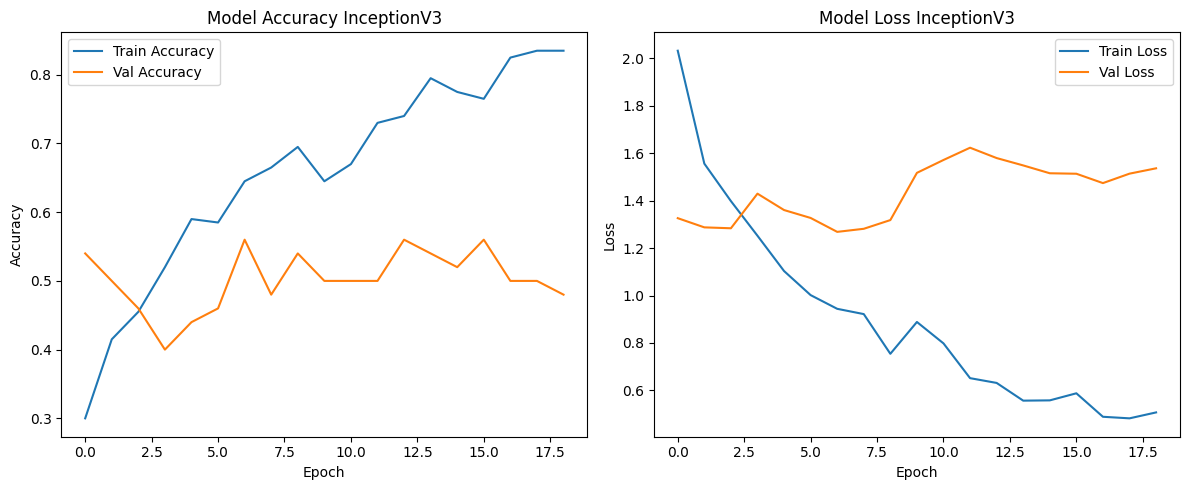

In [20]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_inceptionv3.history['accuracy'], label='Train Accuracy')
plt.plot(history_inceptionv3.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy InceptionV3')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_inceptionv3.history['loss'],     label='Train Loss')
plt.plot(history_inceptionv3.history['val_loss'], label='Val Loss')
plt.title('Model Loss InceptionV3')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.2 Visualize Training InceptionResNetV2

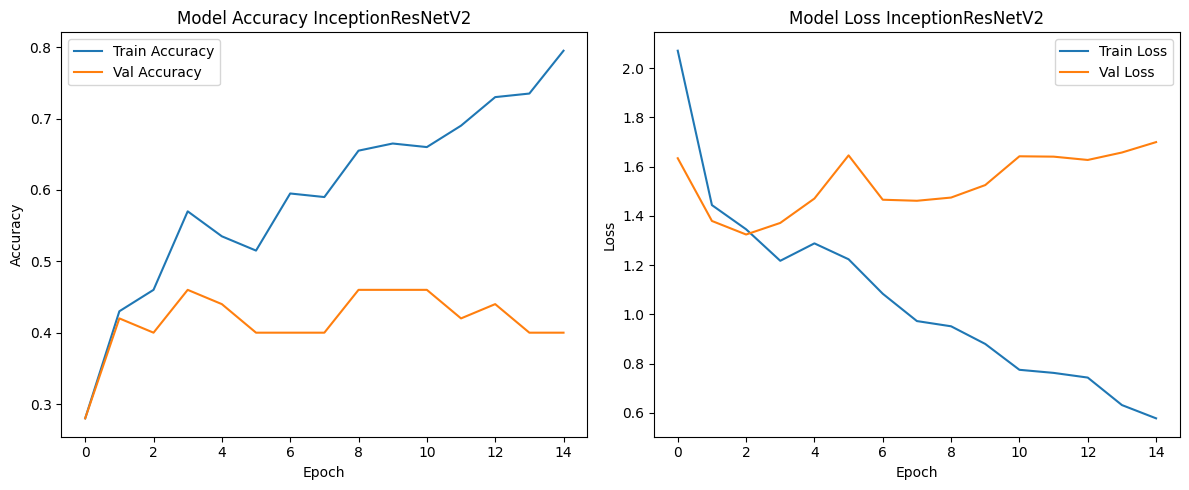

In [21]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_inception_resnetv2.history['accuracy'], label='Train Accuracy')
plt.plot(history_inception_resnetv2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy InceptionResNetV2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_inception_resnetv2.history['loss'],     label='Train Loss')
plt.plot(history_inception_resnetv2.history['val_loss'], label='Val Loss')
plt.title('Model Loss InceptionResNetV2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training Xception

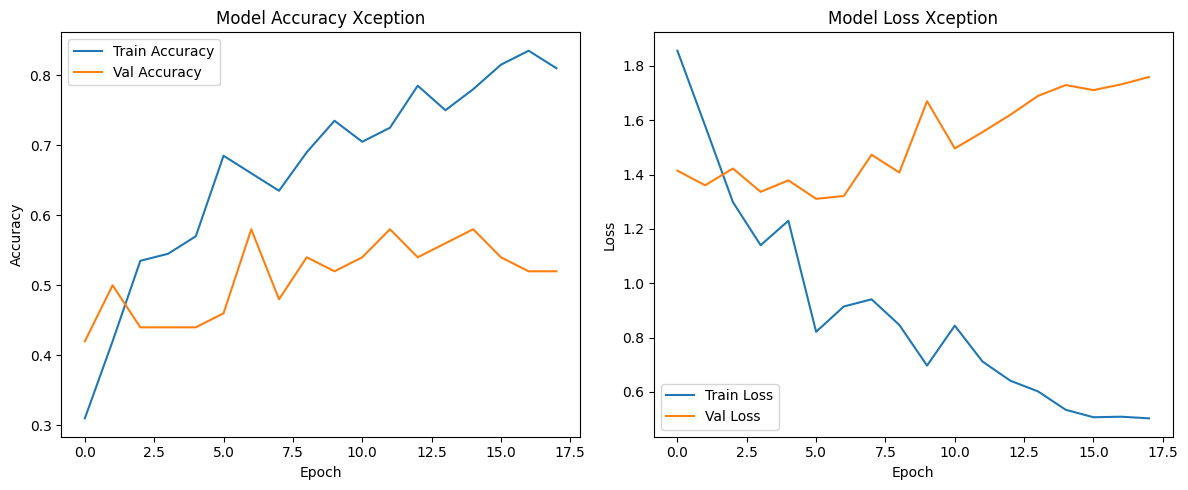

In [22]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_xception.history['accuracy'], label='Train Accuracy')
plt.plot(history_xception.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy Xception')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_xception.history['loss'],     label='Train Loss')
plt.plot(history_xception.history['val_loss'], label='Val Loss')
plt.title('Model Loss Xception')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [23]:
test_loss_inceptionv3, test_acc_inceptionv3 = model_inceptionv3.evaluate(test_dataset_inceptionv3, verbose=0)
print(f'Test Loss InceptionV3: {test_loss_inceptionv3:.4f}')
print(f'Test Accuracy InceptionV3: {test_acc_inceptionv3:.4f}') 

Test Loss InceptionV3: 0.9136
Test Accuracy InceptionV3: 0.6776


In [24]:
test_loss_inception_resnetv2, test_acc_inception_resnetv2 = model_inception_resnetv2.evaluate(test_dataset_inception_resnet_v2, verbose=0)
print(f'Test Loss Inception ResNetV2: {test_loss_inception_resnetv2:.4f}')
print(f'Test Accuracy Inception ResNetV2: {test_acc_inception_resnetv2:.4f}') 

Test Loss Inception ResNetV2: 1.1877
Test Accuracy Inception ResNetV2: 0.4617


In [25]:
test_loss_xception, test_acc_xception = model_xception.evaluate(test_dataset_xception, verbose=0)
print(f'Test Loss InceptionV3: {test_loss_xception:.4f}')
print(f'Test Accuracy InceptionV3: {test_acc_xception:.4f}') 

Test Loss InceptionV3: 1.0936
Test Accuracy InceptionV3: 0.5847
